# Actividades 7 y 8: Ejecución en hardware cuántico real

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

**Actividad 7 (10 %).** Habilitar el acceso a los QPU de IBM con la cuenta de IBM Cloud, ejecutar el circuito de Grover modular en un QPU de
**al menos 127 qubits** y comparar con el simulador.

**Actividad 8.** Reportar Job ID, estado objetivo, número de iteraciones, resultados medidos, probabilidad de éxito y comparación con el simulador.

Se usa el caso de la actividad 4: $n = 3$, estado objetivo $\lvert 111\rangle$ y $k$ calculado automáticamente. El circuito usa 3 qubits lógicos;
el requisito de 127 qubits se refiere al procesador físico. Se ejecutó en dos QPU de 156 qubits, `ibm_fez` e `ibm_kingston`, el 5 de noviembre de 2026.

In [ ]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime

In [ ]:
!pip install -q pylatexenc

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import hellinger_fidelity
from qiskit.visualization import plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
import numpy as np
import csv

## 1. Habilitar el acceso a los QPU de IBM

1. Iniciar sesión en [IBM Quantum Platform](https://quantum.cloud.ibm.com) con la cuenta de IBM Cloud.
2. Crear una **API key** (botón *Create API key* en la página principal).
3. Copiar el **CRN** de la instancia (sección *Instances*; plan *Open*, gratuito, con 10 minutos de QPU al mes).
4. Guardar las credenciales **una sola vez** con `save_account`. Quedan en `~/.qiskit/qiskit-ibm.json`, fuera del repositorio.

> Por seguridad, la API key y el CRN **no** se escriben en este notebook. Para ejecutarlo en otro equipo o en Colab, quite el comentario de la celda
> siguiente, reemplace los valores, ejecútela una vez y vuelva a comentarla antes de guardar o compartir el notebook.

In [4]:
# Ejecutar una sola vez (con la API key y el CRN propios):
# QiskitRuntimeService.save_account(
#     channel='ibm_quantum_platform',
#     token='TU_API_KEY',
#     instance='TU_CRN',
#     set_as_default=True,
#     overwrite=True,
# )

service = QiskitRuntimeService()   # carga la cuenta guardada

# QPU disponibles para la instancia (en el momento de ejecutar esta celda)
for b in service.backends(simulator=False):
    print(f'{b.name:15s} {b.num_qubits:4d} qubits   operativo: {b.status().operational}   trabajos en cola: {b.status().pending_jobs}')

ibm_fez          156 qubits   operativo: True   trabajos en cola: 0


ibm_kingston     156 qubits   operativo: True   trabajos en cola: 2


ibm_marrakesh    156 qubits   operativo: True   trabajos en cola: 0


## 2. Bloques del circuito (actividades 3, 4 y 6)

In [5]:
def Inicializacion(n):
    # Bloque 1: los qubits empiezan en |0...0> (estado inicial de Qiskit).
    # H en cada qubit -> superposición uniforme |s> = (1/sqrt(N)) Σ|x>
    bloque = QuantumCircuit(n, name='Inicialización')
    bloque.h(range(n))
    return bloque


def lista_marcados(MarkState):
    # Acepta un estado ('101') o una lista de estados (['011', '110'])
    return [MarkState] if isinstance(MarkState, str) else list(MarkState)


def Oracle(MarkState):
    # Bloque 2: U_w = I - 2 Σ_w |w><w|  (cambia el signo de cada estado marcado)
    marcados = lista_marcados(MarkState)
    n = len(marcados[0])
    bloque = QuantumCircuit(n, name='Oracle')
    for w in marcados:
        for i, bit in enumerate(reversed(w)):     # X donde el bit = 0: |w> -> |1...1>
            if bit == '0':
                bloque.x(i)
        bloque.h(n - 1)                           # Z multicontrolada = H · MCX · H
        bloque.mcx(list(range(n - 1)), n - 1)
        bloque.h(n - 1)
        for i, bit in enumerate(reversed(w)):     # deshacer las X
            if bit == '0':
                bloque.x(i)
    return bloque


def Difusor(n):
    # Bloque 3: H^n (I - 2|0><0|) H^n = -(2|s><s| - I)  -> inversión sobre la media
    bloque = QuantumCircuit(n, name='Difusor')
    bloque.h(range(n))
    bloque.x(range(n))
    bloque.h(n - 1)
    bloque.mcx(list(range(n - 1)), n - 1)         # Z multicontrolada
    bloque.h(n - 1)
    bloque.x(range(n))
    bloque.h(range(n))
    return bloque


def OperadorGrover(qc, MarkState):
    # Una iteración del operador de Grover G = Difusor · Oracle, aplicada sobre qc
    n = qc.num_qubits
    qubits = list(range(n))
    qc.append(Oracle(MarkState).to_gate(label='Oracle'), qubits)
    qc.barrier()
    qc.append(Difusor(n).to_gate(label='Difusor'), qubits)
    qc.barrier()


def Medicion(n):
    # Bloque 4: q_i -> c_i
    bloque = QuantumCircuit(n, n, name='Medición')
    bloque.measure(range(n), range(n))
    return bloque


def Iteraciones(n, M=1):
    """
    Número de iteraciones de Grover: k ≈ (π/4)·√(N/M), con N = 2^n y M estados marcados.
    Se toma la parte entera (floor) para no pasarse del ángulo π/2.
    Casos límite:
      - M < 1 o M > N: no tiene sentido -> error.
      - M ≥ N/2: iterar no mejora (medir |s> ya da éxito M/N ≥ 1/2) -> k = 0.
    """
    N = 2**n
    if not 1 <= M <= N:
        raise ValueError(f'M debe estar entre 1 y N = {N}; se recibió M = {M}')
    if M >= N / 2:
        return 0
    return int(np.floor(np.pi / 4 * np.sqrt(N / M)))


def Grover(n, MarkState, num_iteraciones=None, medir=True):
    # Inicialización -> (Oracle -> Difusor) x k -> Medición
    marcados = lista_marcados(MarkState)
    if any(len(w) != n for w in marcados):
        raise ValueError('Cada estado marcado debe tener n dígitos')
    if num_iteraciones is None:
        num_iteraciones = Iteraciones(n, len(marcados))   # k automático
    qubits = list(range(n))
    qc = QuantumCircuit(n, n) if medir else QuantumCircuit(n)

    qc.append(Inicializacion(n).to_gate(label='Inicialización'), qubits)
    qc.barrier()
    for _ in range(num_iteraciones):
        OperadorGrover(qc, marcados)
    if medir:
        qc.compose(Medicion(n), qubits=qubits, clbits=qubits, inplace=True)
    return qc

Número de iteraciones k = 2


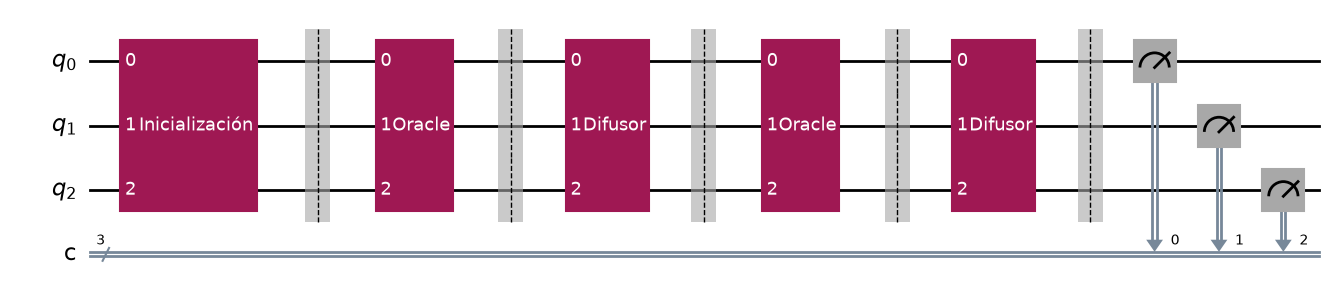

In [6]:
# Parámetros del experimento
n = 3
MarkState = '111'      # estado objetivo (el mismo del tutorial y de la actividad 4)
k = Iteraciones(n)     # k automático
shots = 4096

grover_circuit = Grover(n, MarkState)
print('Número de iteraciones k =', k)
grover_circuit.draw('mpl')

## 3. Transpilación y ejecución en el QPU

Para enviar un trabajo nuevo se elige el QPU **menos ocupado con al menos 127 qubits** (`least_busy`). El transpilador traduce el circuito a las compuertas
nativas del equipo ($R_z$, $\sqrt X$, $X$ y $CZ$), lo ajusta a la conectividad de sus qubits y elige qubits físicos (`optimization_level=3`).

`JOBS` guarda los dos trabajos que ya se ejecutaron, para recuperar sus resultados sin volver a gastar tiempo de QPU.
Con `JOBS = None` se envía un trabajo nuevo.

In [7]:
JOBS = {'ibm_fez': 'dbmeatt8mdtc73d7qpc0',          # trabajos ya ejecutados (5 de noviembre de 2026)
        'ibm_kingston': 'dbmdvgt8ft8s738umv00'}     # None para enviar uno nuevo

if JOBS is None:
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=2026)
    job = Sampler(mode=backend).run([pm.run(grover_circuit)], shots=shots)
    JOBS = {backend.name: job.job_id()}
    print('Trabajo enviado a', backend.name, '-> Job ID:', job.job_id())

ejecuciones = {}
for nombre, job_id in JOBS.items():
    job = service.job(job_id)
    backend_job = job.backend()
    isa_enviado = job.inputs['pubs'][0][0]               # circuito exacto que se ejecutó
    shots_job = job.inputs['pubs'][0][2]
    counts = job.result()[0].data.c.get_counts()

    # El mismo circuito transpilado aquí (misma semilla) debe coincidir con el enviado
    isa_local = generate_preset_pass_manager(backend=backend_job, optimization_level=3,
                                             seed_transpiler=2026).run(grover_circuit)
    ejecuciones[nombre] = dict(job=job, backend=backend_job, isa=isa_enviado, counts=counts, shots=shots_job)

    print(f'QPU {backend_job.name} ({backend_job.num_qubits} qubits)')
    print(f'  Job ID           : {job.job_id()}   estado: {job.status()}   creado: {job.creation_date:%Y-%m-%d %H:%M}')
    print(f'  Disparos         : {shots_job}')
    print(f'  Circuito enviado : profundidad {isa_enviado.depth()}, {dict(isa_enviado.count_ops())}')
    print(f'  ¿Coincide con el transpilado local? ',
          isa_local.depth() == isa_enviado.depth() and dict(isa_local.count_ops()) == dict(isa_enviado.count_ops()))
    print(f'  Qubits físicos   : {[isa_local.layout.final_index_layout()[i] for i in range(n)]}')
    print(f'  Tiempo de QPU    : {job.metrics()["usage"].get("qpu_charge_time_seconds")} s')
    print(f'  Conteos          : {counts}')

QPU ibm_fez (156 qubits)
  Job ID           : dbmeatt8mdtc73d7qpc0   estado: DONE   creado: 2026-11-05 15:22
  Disparos         : 4096
  Circuito enviado : profundidad 152, {'sx': 79, 'rz': 71, 'cz': 39, 'x': 6, 'barrier': 5, 'measure': 3}
  ¿Coincide con el transpilado local?  True
  Qubits físicos   : [16, 23, 22]
  Tiempo de QPU    : 3 s
  Conteos          : {'100': 112, '111': 3255, '010': 91, '001': 107, '110': 153, '101': 148, '000': 83, '011': 147}


QPU ibm_kingston (156 qubits)
  Job ID           : dbmdvgt8ft8s738umv00   estado: DONE   creado: 2026-11-05 14:57
  Disparos         : 4096
  Circuito enviado : profundidad 152, {'sx': 79, 'rz': 71, 'cz': 39, 'x': 6, 'barrier': 5, 'measure': 3}
  ¿Coincide con el transpilado local?  True
  Qubits físicos   : [75, 59, 55]
  Tiempo de QPU    : 3 s
  Conteos          : {'111': 3444, '101': 88, '001': 74, '010': 62, '000': 76, '011': 159, '100': 82, '110': 111}


## 4. Simuladores para comparar

- **Ideal**: `AerSimulator` sin ruido (como en las actividades anteriores), con los mismos 4096 disparos.
- **Con ruido**: `AerSimulator.from_backend(...)` con el modelo de errores de cada QPU, aplicado al **mismo circuito que se ejecutó**.
  El modelo usa la calibración vigente **cuando se ejecuta esta celda**, que puede diferir de la del momento en que corrió el trabajo.
- **Teórica**: $P_{\text{éxito}} = \sin^2\big((2k+1)\theta\big)$ con $\sin\theta = 1/\sqrt{2^n}$.

In [8]:
sim_ideal = AerSimulator(seed_simulator=2026)
counts_ideal = sim_ideal.run(transpile(grover_circuit, sim_ideal), shots=shots).result().get_counts()

for nombre, e in ejecuciones.items():
    sim_ruido = AerSimulator.from_backend(e['backend'], seed_simulator=2026)
    e['counts_ruido'] = sim_ruido.run(e['isa'], shots=shots).result().get_counts()

theta = np.arcsin(1 / np.sqrt(2**n))
p_teorica = np.sin((2 * k + 1) * theta)**2

print('Ideal                :', counts_ideal)
for nombre, e in ejecuciones.items():
    print(f'Ruido de {nombre:13s}:', e['counts_ruido'])

Ideal                : {'110': 29, '100': 23, '001': 26, '000': 37, '010': 37, '101': 42, '011': 42, '111': 3860}
Ruido de ibm_fez      : {'000': 71, '010': 68, '110': 95, '001': 87, '100': 79, '111': 3480, '011': 96, '101': 120}
Ruido de ibm_kingston : {'101': 85, '001': 76, '100': 56, '110': 114, '000': 63, '010': 58, '011': 116, '111': 3528}


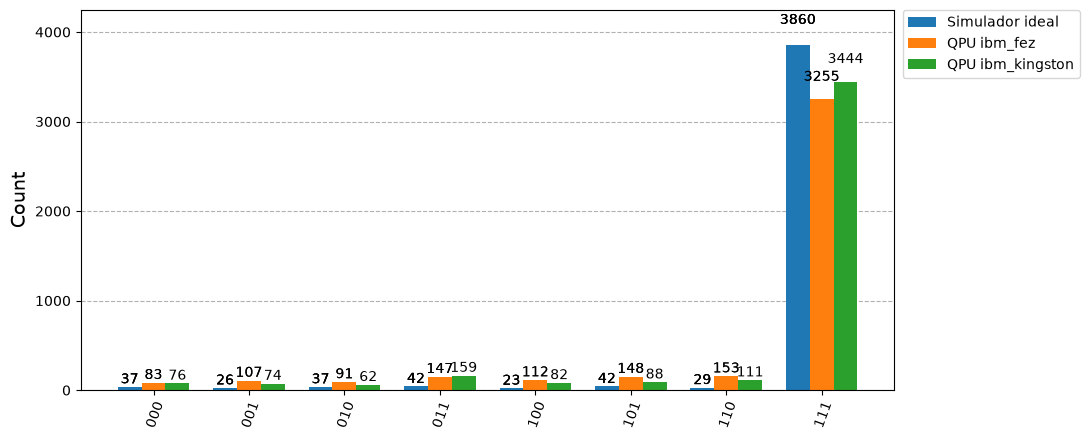

In [9]:
figura = plot_histogram([counts_ideal] + [e['counts'] for e in ejecuciones.values()],
                        legend=['Simulador ideal'] + [f'QPU {nombre}' for nombre in ejecuciones],
                        figsize=(11, 4.5))
figura.savefig('../figuras/comparacion_simulador_qpu.png', dpi=150, bbox_inches='tight')
figura

## 5. Reporte de resultados (actividad 8)

In [10]:
def p(c, estado):
    return c.get(estado, 0) / sum(c.values())

estados = [f'{i:0{n}b}' for i in range(2**n)]

print('=' * 72)
print('REPORTE - EJECUCIÓN EN HARDWARE CUÁNTICO REAL')
print('=' * 72)
print(f'Estado objetivo        : |{MarkState}>')
print(f'Qubits del circuito    : {n}')
print(f'Número de iteraciones  : k = {k}')
for nombre, e in ejecuciones.items():
    print(f'{nombre:23s}: Job ID {e["job"].job_id()}, {e["backend"].num_qubits} qubits físicos, '
          f'{e["shots"]} disparos, más medido |{max(e["counts"], key=e["counts"].get)}>')
print()
cab = ''.join(f'{nombre:>14}' for nombre in ejecuciones)
print(f"{'Estado':>8}{cab}{'Sim. ideal':>12}")
for est in estados:
    fila = ''.join(f"{e['counts'].get(est, 0):>14}" for e in ejecuciones.values())
    marca = '  <- objetivo' if est == MarkState else ''
    print(f"{est:>8}{fila}{counts_ideal.get(est, 0):>12}{marca}")
print()
print(f"{'':28s}{'P(' + MarkState + ')':>8}{'Hellinger vs ideal':>20}")
print(f"{'Teórica':28s}{p_teorica:>8.4f}")
print(f"{'Simulador ideal':28s}{p(counts_ideal, MarkState):>8.4f}")
for nombre, e in ejecuciones.items():
    print(f"{'Simulador con ruido ' + nombre:28s}{p(e['counts_ruido'], MarkState):>8.4f}{hellinger_fidelity(counts_ideal, e['counts_ruido']):>20.4f}")
    print(f"{'QPU real ' + nombre:28s}{p(e['counts'], MarkState):>8.4f}{hellinger_fidelity(counts_ideal, e['counts']):>20.4f}")
print(f"{'Azar (1/2^n)':28s}{1 / 2**n:>8.4f}")

# Guardar los conteos
with open('../resultados/resultados_qpu.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['estado'] + [f'qpu_{nombre}' for nombre in ejecuciones] + [f'sim_ruido_{nombre}' for nombre in ejecuciones] + ['sim_ideal'])
    for est in estados:
        w.writerow([est] + [e['counts'].get(est, 0) for e in ejecuciones.values()]
                   + [e['counts_ruido'].get(est, 0) for e in ejecuciones.values()] + [counts_ideal.get(est, 0)])
print('\nConteos guardados en ../resultados/resultados_qpu.csv')

REPORTE - EJECUCIÓN EN HARDWARE CUÁNTICO REAL
Estado objetivo        : |111>
Qubits del circuito    : 3
Número de iteraciones  : k = 2
ibm_fez                : Job ID dbmeatt8mdtc73d7qpc0, 156 qubits físicos, 4096 disparos, más medido |111>
ibm_kingston           : Job ID dbmdvgt8ft8s738umv00, 156 qubits físicos, 4096 disparos, más medido |111>

  Estado       ibm_fez  ibm_kingston  Sim. ideal
     000            83            76          37
     001           107            74          26
     010            91            62          37
     011           147           159          42
     100           112            82          23
     101           148            88          42
     110           153           111          29
     111          3255          3444        3860  <- objetivo

                              P(111)  Hellinger vs ideal
Teórica                       0.9453
Simulador ideal               0.9424
Simulador con ruido ibm_fez   0.8496              0.9746
QPU real 

## 6. Reporte final (actividad 8)

| Dato | `ibm_fez` | `ibm_kingston` |
|---|---|---|
| Job ID | `dbmeatt8mdtc73d7qpc0` | `dbmdvgt8ft8s738umv00` |
| Capacidad física del QPU | 156 qubits | 156 qubits |
| Qubits del circuito (físicos usados) | 3 (16, 23, 22) | 3 (75, 59, 55) |
| Estado objetivo | $\lvert 111\rangle$ | $\lvert 111\rangle$ |
| Iteraciones | $k = \lfloor \frac{\pi}{4}\sqrt{8}\rfloor = 2$ | $k = 2$ |
| Disparos | 4096 | 4096 |
| Circuito transpilado | profundidad 152, 39 CZ | profundidad 152, 39 CZ |
| Resultados medidos | `{'111': 3255, '110': 153, '101': 148, '011': 147, '100': 112, '001': 107, '010': 91, '000': 83}` | `{'111': 3444, '011': 159, '110': 111, '101': 88, '100': 82, '000': 76, '001': 74, '010': 62}` |
| **Probabilidad de éxito (QPU)** | **0.7947** | **0.8408** |
| Simulador con su modelo de ruido | 0.8496 | 0.8613 |
| Fidelidad de Hellinger vs. ideal (QPU) | 0.9468 | 0.9697 |
| Tiempo de QPU cobrado | 3 s | 3 s |

Referencias: **simulador ideal 0.9424** (4096 disparos), **teórica** $\sin^2(5\theta) =$ **0.9453**, azar $1/8 = 0.125$.

### Comparación con el simulador

1. **El algoritmo funciona en hardware real.** En los dos QPU $\lvert 111\rangle$ es por mucho el resultado más frecuente: 0.795 y 0.841, frente a 0.125 que daría
   una elección al azar (6 a 7 veces más). Cada uno de los otros siete estados queda entre 1.5 % y 4 %.
2. **Los QPU pierden entre 10 y 15 puntos frente al simulador ideal** (0.942). Antes de atribuirlo al ruido se revisó la configuración:
   - El circuito ejecutado es el mismo que se transpila aquí (misma profundidad y mismas compuertas), con los mismos 4096 disparos y el mismo $k = 2$ que en el simulador.
   - Los trabajos corrieron con las opciones por defecto del Sampler (`options: {}`): **sin** desacoplamiento dinámico, sin *twirling* y sin mitigación de errores de lectura.
     Ninguna técnica de supresión o mitigación ayudó al resultado.
   - Las barreras entre bloques no cambian el número de CZ (39 con y sin barreras); solo suben la profundidad de 140 a 152.
   - La variación estadística con 4096 disparos es de $\pm 0.006$ aproximadamente, muy por debajo de la diferencia observada.
3. **El costo está en las compuertas de dos qubits.** El circuito de 3 qubits tiene cuatro Toffoli (`mcx` con 2 controles: una en el oracle y otra en el difusor,
   por cada una de las 2 iteraciones). Cada Toffoli se descompone en varias CZ, y como los tres qubits físicos no están todos conectados entre sí,
   el transpilador agrega compuertas para moverlos: en total **39 CZ** y profundidad 152. Errores de las CZ, decoherencia durante la ejecución y errores de lectura
   se acumulan.
4. **El modelo de ruido explica la mayor parte de la diferencia.** Simulando el mismo circuito con el ruido calibrado de cada equipo, el éxito baja a 0.850 (fez)
   y 0.861 (kingston). En `ibm_kingston` el modelo queda cerca del resultado real (0.861 frente a 0.841); en `ibm_fez` el QPU queda más abajo (0.795 frente a 0.850).
   El modelo usa la calibración vigente al ejecutar este notebook, no la del momento del trabajo, y no incluye todos los efectos reales (por ejemplo, la
   interferencia entre qubits vecinos).
5. **Diferencia entre equipos.** Con el mismo circuito, el mismo número de CZ y la misma profundidad, `ibm_kingston` dio mejor resultado que `ibm_fez`.
   La calidad depende de los qubits físicos usados y de su calibración en el momento de la ejecución.
6. **Dónde caen los errores.** Los estados que difieren de $\lvert 111\rangle$ en un solo bit son los errores más frecuentes: en fez $\lvert 110\rangle$, $\lvert 101\rangle$ y
   $\lvert 011\rangle$ (153, 148 y 147); en kingston $\lvert 011\rangle$ y $\lvert 110\rangle$ (159 y 111). $\lvert 000\rangle$, que difiere en los tres bits, aparece menos
   (83 y 76). Es lo esperable si muchos errores invierten un solo qubit, por ejemplo en la lectura.

**Conclusión.** Con el $k$ calculado automáticamente, el algoritmo de Grover encuentra el estado objetivo en hardware real con probabilidad 0.795 (`ibm_fez`) y
0.841 (`ibm_kingston`). Es menos que el 0.945 teórico por el ruido del hardware, pero sigue siendo claramente mayor que el azar. Activar desacoplamiento dinámico
o mitigación de errores de lectura podría mejorar el resultado; no se probó para no gastar más tiempo de QPU. Para $n$ más grande la Z multicontrolada necesita
muchas más CZ y el ruido reduciría más la probabilidad de éxito.

In [11]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from qiskit_ibm_runtime import __version__ as runtime_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Qiskit_IBM_Runtime Version:', runtime_version)
print('Python Version:', python_version())
print('UdeA-Medellin (2026) ©')

Qiskit Version: 2.5.2
Qiskit_Aer Version: 0.18.2
Qiskit_IBM_Runtime Version: 0.51.0
Python Version: 3.13.14
UdeA-Medellin (2026) ©
